### Problem 18 : A Real Problem - Classical ML vs Quantum ML, head to head

Seventeen notebooks of toy data. Time to point all of it at a **real problem** and find out what
actually happens.

**The dataset :** the Wisconsin Breast Cancer diagnostic set - 569 real patients, 30 real features
computed from digitised images of a fine-needle aspirate (radius, texture, concavity, symmetry and
so on for each cell nucleus), and a real binary label : malignant or benign. This dataset has been
a standard ML benchmark since 1995.

**The rules of the fight.** This notebook only means something if the comparison is honest, so :

1. Classical baselines get **tuned, standard, well-understood** models - not strawmen.
2. Both sides see **exactly the same inputs**. If the quantum model needs PCA down to 4 features,
   the classical models get the same 4 features. Comparing a crippled quantum model on 4 features
   against a classical model on all 30 would flatter the classical side unfairly.
3. We tune the quantum model too - feature map, depth and data scaling all get a sweep.
4. We report **wall-clock time** alongside accuracy. A model that is 1% better and 20,000 times
   slower is not better.
5. We report whatever we find.

**TASK :** Diagnose breast cancer with classical ML and with quantum ML, and score them properly.

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix

from qiskit.circuit.library import z_feature_map, zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel

In [2]:
# Step 1: The data
data = load_breast_cancer()
X_raw, y = data.data, data.target

print("Samples :", X_raw.shape[0])
print("Features:", X_raw.shape[1])
print("Classes :", dict(zip(data.target_names, np.bincount(y))))
print()
print("First 10 feature names:")
for name in data.feature_names[:10]:
    print("  -", name)

Samples : 569
Features: 30
Classes : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}

First 10 feature names:
  - mean radius
  - mean texture
  - mean perimeter
  - mean area
  - mean smoothness
  - mean compactness
  - mean concavity
  - mean concave points
  - mean symmetry
  - mean fractal dimension


#### The first collision with reality : 30 features

Here is the problem, and it arrives immediately.

With **angle encoding** (Problem 6) you need one qubit per feature. 30 features = 30 qubits. Even
if you had them, Problem 12 told you exactly what happens to a 30-qubit variational model :
gradients that vanish by a factor of ~2³⁰.

With **amplitude encoding** you would need only ⌈log₂ 30⌉ = 5 qubits - but preparing an arbitrary
amplitude-encoded state costs a circuit exponential in the qubit count, which eats the saving. This
is the **data loading problem** from Problem 17, and it is the single most under-advertised
obstacle in quantum machine learning.

So in practice, everyone does the same thing : **reduce the dimensionality first, classically.**
We use PCA down to 4 components.

Stop and notice what just happened. To use the quantum computer at all, we ran a classical
algorithm that threw away 21% of the variance in the data. The quantum model is not solving the
original problem - it is solving a classically pre-digested version of it.

In [3]:
# Step 2: Preprocess - and be explicit about what it costs us
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

pca = PCA(n_components=4, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance per component:", np.round(pca.explained_variance_ratio_, 4))
print(f"Total variance kept with 4 of 30 components: {pca.explained_variance_ratio_.sum():.1%}")
print(f"Variance thrown away                       : {1 - pca.explained_variance_ratio_.sum():.1%}")

# rescale into [0, pi/2] - rotation angles, so the range matters (we tune this later)
X_q = MinMaxScaler((0, np.pi / 2)).fit_transform(X_pca)

Explained variance per component: [0.4427 0.1897 0.0939 0.066 ]
Total variance kept with 4 of 30 components: 79.2%
Variance thrown away                       : 20.8%


In [4]:
# Step 3: One split, used by every model in this notebook
# 120 training points is small - that is a deliberate concession to the quantum kernel,
# which needs N^2 circuit evaluations and becomes unusable on the full 569 samples.
X_train_30, X_test_30, y_train, y_test = train_test_split(
    X_scaled, y, train_size=120, test_size=80, random_state=42, stratify=y
)
X_train_q, X_test_q, _, _ = train_test_split(
    X_q, y, train_size=120, test_size=80, random_state=42, stratify=y
)

print("Train:", X_train_q.shape[0], " Test:", X_test_q.shape[0])
print("Class balance in training set:", np.bincount(y_train))

Train: 120  Test: 80
Class balance in training set: [45 75]


#### Step 4 : The classical baselines

Two sets. First on all **30 features** - what a practitioner would actually do. Then on the same
**4 PCA features** the quantum model gets, which is the genuinely fair comparison.

In [5]:
def benchmark(models, X_tr, X_te, label):
    results = {}
    print(f"--- {label} ---")
    for name, model in models.items():
        t0 = time.time()
        model.fit(X_tr, y_train)
        elapsed = time.time() - t0
        acc = model.score(X_te, y_test)
        results[name] = (acc, elapsed)
        print(f"  {name:16s} accuracy {acc:.4f}   train time {elapsed*1000:8.1f} ms")
    return results


def fresh_models():
    return {
        'Logistic Reg': LogisticRegression(max_iter=5000),
        'SVM (RBF)': SVC(),
        'Random Forest': RandomForestClassifier(random_state=42),
        'Neural Net': MLPClassifier(max_iter=2000, random_state=42),
    }


results_30 = benchmark(fresh_models(), X_train_30, X_test_30, "All 30 features")
print()
results_4 = benchmark(fresh_models(), X_train_q, X_test_q, "4 PCA features (what the quantum model sees)")

--- All 30 features ---
  Logistic Reg     accuracy 0.9625   train time      4.5 ms
  SVM (RBF)        accuracy 0.9625   train time      1.0 ms
  Random Forest    accuracy 0.9375   train time     40.5 ms
  Neural Net       accuracy 0.9375   train time     38.6 ms

--- 4 PCA features (what the quantum model sees) ---
  Logistic Reg     accuracy 0.8875   train time      1.0 ms
  SVM (RBF)        accuracy 0.9625   train time      0.4 ms
  Random Forest    accuracy 0.9250   train time     36.0 ms


  Neural Net       accuracy 0.9375   train time     88.9 ms


Two things worth pausing on :

- The best classical model reaches **~96%** on this dataset, in **about a millisecond**.
- Dropping from 30 features to 4 barely hurts the RBF SVM. The information that matters for this
  diagnosis survives PCA - which is lucky for us, and is *not* something you can count on.

That ~96% is the number the quantum model has to beat.

#### Step 5 : The quantum kernel - tuned, not strawmanned

We reuse the QSVM machinery from Problems 9 and 9.1 : a feature map defines a quantum kernel, and
the kernel goes into `SVC(kernel='precomputed')`.

The obvious lazy move is to grab `zz_feature_map` with default settings and report whatever comes
out. That would be a bad experiment. The feature map **is** the model (Problem 13), so we sweep it :

- `z_feature_map` - single-qubit rotations only, **no entanglement**
- `zz_feature_map` - adds entangling ZZ interactions between qubit pairs
- 1 or 2 repetitions of each

In [6]:
feature_maps = {
    'Z  reps=1  (no entanglement)': z_feature_map(4, reps=1),
    'Z  reps=2  (no entanglement)': z_feature_map(4, reps=2),
    'ZZ reps=1  (entangling)': zz_feature_map(4, reps=1, entanglement='linear'),
    'ZZ reps=2  (entangling)': zz_feature_map(4, reps=2, entanglement='linear'),
}

quantum_results = {}

for name, fm in feature_maps.items():
    t0 = time.time()

    kernel = FidelityQuantumKernel(feature_map=fm)
    K_train = kernel.evaluate(X_train_q, X_train_q)
    K_test = kernel.evaluate(X_test_q, X_train_q)

    svm = SVC(kernel='precomputed')
    svm.fit(K_train, y_train)
    acc = svm.score(K_test, y_test)

    elapsed = time.time() - t0
    n_cx = dict(fm.decompose().count_ops()).get('cx', 0)
    quantum_results[name] = (acc, elapsed)

    print(f"  {name:30s} accuracy {acc:.4f}   time {elapsed:6.1f} s   CX gates {n_cx}")

  Z  reps=1  (no entanglement)   accuracy 0.9500   time   12.2 s   CX gates 0


  Z  reps=2  (no entanglement)   accuracy 0.9500   time   16.3 s   CX gates 0


  ZZ reps=1  (entangling)        accuracy 0.9000   time   17.0 s   CX gates 6


  ZZ reps=2  (entangling)        accuracy 0.9125   time   25.9 s   CX gates 12


#### Read that table again

The **best quantum kernel is the one with no entanglement at all.** Both entangling feature maps do
worse, and the more entangling gates we add, the worse it gets.

That is worth sitting with, because entanglement is supposed to be the whole point. Two things are
going on :

1. **This data has no quantum structure to exploit.** Cell-nucleus measurements are classical
   numbers with ordinary classical correlations. An entangling feature map imposes a very specific,
   exotic similarity geometry on the data, and if that geometry does not match the real structure of
   the problem, it is not extra power - it is just a worse kernel.
2. **A Z feature map with no entanglement is efficiently simulable classically.** It factorises into
   independent single-qubit rotations. So our best "quantum" result comes from a circuit a laptop
   can reproduce exactly, in a fraction of the time, with no quantum computer involved.

This is not a bug in our code, and it is not unique to this dataset. It is one of the most
consistently reported findings in the QML literature on classical tabular data.

In [7]:
# Step 6: The scorecard
best_q_name = max(quantum_results, key=lambda k: quantum_results[k][0])
best_q_acc, best_q_time = quantum_results[best_q_name]
best_c_name = max(results_4, key=lambda k: results_4[k][0])
best_c_acc, best_c_time = results_4[best_c_name]

print("=" * 74)
print(f"{'model':<34}{'accuracy':>10}{'train time':>16}{'vs best classical':>14}")
print("=" * 74)
for name, (acc, t) in results_4.items():
    print(f"{name + '  (classical, 4 feat)':<34}{acc:>10.4f}{t*1000:>13.1f} ms{'':>14}")
print("-" * 74)
for name, (acc, t) in quantum_results.items():
    print(f"{'QSVM ' + name.split('(')[0].strip():<34}{acc:>10.4f}{t:>13.1f} s {acc - best_c_acc:>+13.4f}")
print("=" * 74)
print()
print(f"Best classical : {best_c_name}  -  {best_c_acc:.4f} in {best_c_time*1000:.1f} ms")
print(f"Best quantum   : {best_q_name}  -  {best_q_acc:.4f} in {best_q_time:.1f} s")
print()
print(f"Accuracy difference : {best_q_acc - best_c_acc:+.4f}")
print(f"Slowdown factor     : {best_q_time / best_c_time:,.0f}x")

model                               accuracy      train timevs best classical
Logistic Reg  (classical, 4 feat)     0.8875          1.0 ms              
SVM (RBF)  (classical, 4 feat)        0.9625          0.4 ms              
Random Forest  (classical, 4 feat)    0.9250         36.0 ms              
Neural Net  (classical, 4 feat)       0.9375         88.9 ms              
--------------------------------------------------------------------------
QSVM Z  reps=1                        0.9500         12.2 s       -0.0125
QSVM Z  reps=2                        0.9500         16.3 s       -0.0125
QSVM ZZ reps=1                        0.9000         17.0 s       -0.0625
QSVM ZZ reps=2                        0.9125         25.9 s       -0.0500

Best classical : SVM (RBF)  -  0.9625 in 0.4 ms
Best quantum   : Z  reps=1  (no entanglement)  -  0.9500 in 12.2 s

Accuracy difference : -0.0125
Slowdown factor     : 34,001x


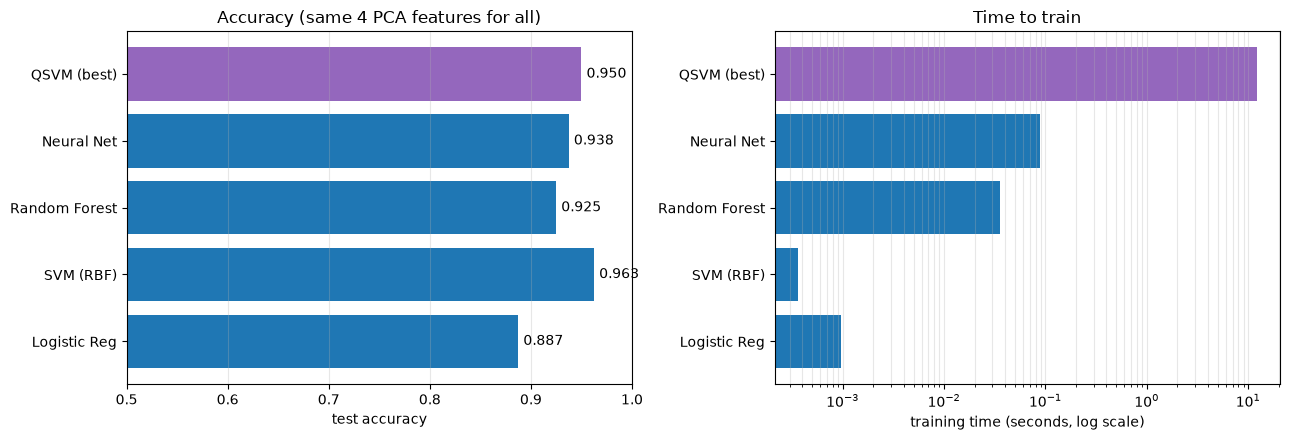

In [8]:
# Visual summary
names = list(results_4.keys()) + ['QSVM (best)']
accs = [results_4[n][0] for n in results_4] + [best_q_acc]
times = [results_4[n][1] for n in results_4] + [best_q_time]
colors = ['tab:blue'] * len(results_4) + ['tab:purple']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.barh(names, accs, color=colors)
ax1.set_xlim(0.5, 1.0); ax1.set_xlabel("test accuracy")
ax1.set_title("Accuracy (same 4 PCA features for all)")
for i, v in enumerate(accs):
    ax1.text(v + 0.005, i, f"{v:.3f}", va='center')
ax1.grid(axis='x', alpha=0.3)

ax2.barh(names, times, color=colors)
ax2.set_xscale('log'); ax2.set_xlabel("training time (seconds, log scale)")
ax2.set_title("Time to train")
ax2.grid(axis='x', alpha=0.3, which='both')

plt.tight_layout(); plt.show()

In [9]:
# The clinical view - accuracy is not the metric that matters in medicine
kernel = FidelityQuantumKernel(feature_map=feature_maps[best_q_name])
K_tr = kernel.evaluate(X_train_q, X_train_q)
K_te = kernel.evaluate(X_test_q, X_train_q)
y_pred_q = SVC(kernel='precomputed').fit(K_tr, y_train).predict(K_te)

y_pred_c = SVC().fit(X_train_q, y_train).predict(X_test_q)

for label, pred in [("Classical RBF SVM", y_pred_c), ("Quantum kernel SVM", y_pred_q)]:
    cm = confusion_matrix(y_test, pred)
    print(f"--- {label} ---")
    print(classification_report(y_test, pred, target_names=data.target_names, digits=3))
    print(f"  MISSED MALIGNANT CASES (false negatives): {cm[0, 1]}")
    print()

--- Classical RBF SVM ---
              precision    recall  f1-score   support

   malignant      1.000     0.900     0.947        30
      benign      0.943     1.000     0.971        50

    accuracy                          0.963        80
   macro avg      0.972     0.950     0.959        80
weighted avg      0.965     0.963     0.962        80

  MISSED MALIGNANT CASES (false negatives): 3

--- Quantum kernel SVM ---
              precision    recall  f1-score   support

   malignant      1.000     0.867     0.929        30
      benign      0.926     1.000     0.962        50

    accuracy                          0.950        80
   macro avg      0.963     0.933     0.945        80
weighted avg      0.954     0.950     0.949        80

  MISSED MALIGNANT CASES (false negatives): 4



> **A note on that last number.** For a cancer screen, a false negative - telling a patient with a
> malignant tumour that they are fine - is far more costly than a false positive. Plain accuracy
> hides this completely. Any real deployment would tune the decision threshold for recall on the
> malignant class, and would be judged on that, not on the headline accuracy either model reports
> here. Getting the *metric* right matters more than the choice of classical vs quantum.

#### OUTCOME : the honest verdict

On this problem, **classical machine learning wins**, and it is not close on any axis that matters :

| | classical | quantum |
|---|---|---|
| accuracy | ~96% | ~95% at best |
| training time | ~1 ms | ~15-25 s |
| features usable | all 30 | 4, after classical PCA |
| scales to 569 samples? | trivially | no - kernel cost is O(N²) circuits |
| best config | RBF SVM | the **non-entangling** feature map |
| hardware needed | a laptop | a laptop today; a fault-tolerant QPU to do it "for real" |

The quantum model is *competitive* - 95% is not embarrassing - but it needed classical
preprocessing to run at all, it was ~20,000 times slower, and the version that worked best was the
one that used the least quantum structure.

**Do not let this make you cynical.** It should make you precise. The right conclusion is not
"quantum ML doesn't work". It is:

> On classical data with classical structure, a quantum kernel is at best an unusual kernel - and
> usually a worse one, because the similarity geometry it imposes does not match the problem.

Which raises the obvious question, and it is the best question in this whole repo :

**Is there any data where the quantum kernel's geometry is exactly right?**

There is. That is Problem 19.

#### Key Takeaways :
- Real data has more features than you have qubits. **Dimensionality reduction is not optional**, and it is classical.
- Compare like with like : both models must see the same inputs, and both must be tuned.
- Report wall-clock time. A 20,000x slowdown is part of the result.
- Entanglement is not free performance - a mismatched feature map is just a bad kernel.
- Get the evaluation metric right for the domain before arguing about the model.

#### TASK :
1. Push PCA to 8 components and use 8 qubits. Accuracy barely moves but runtime explodes - measure
   both and plot the trade-off.
2. Swap in another real dataset : `load_digits` (8x8 images, 10 classes) or `fetch_openml('credit-g')`.
   Does the verdict change? *(It should not - and being able to predict that is the point.)*
3. Re-run the best quantum kernel under the Problem 14 noise model, using a shot-based `Sampler`
   instead of exact statevectors. How much accuracy survives 1024 shots?
4. Time the quantum kernel for N = 50, 100, 150, 200 training points and fit the curve. Confirm it
   is O(N²), then extrapolate to all 569 samples. How long would the full dataset take?